# Model validation

Started: 13.01.2025

## Welch 2009

### Load sequences

In [2]:
include("packages.jl") 

df = readmatrix("../data/input/Welch_2009.xlsx", "table1", "A1:C79") # sequence and expression data from Welch 2009

# Create table
headers = df[1, 1:2]
data	= df[2:end,1:2] # 2:43
df      = DataFrame(data, headers)
df      = subset(df, :expression .=> ByRow(x -> x != "nd"), skipmissing=false)
sequence_names = string.(df[1:end,1]); # sequence names 


🔧 Julia started with 8 threads


### Translation rate of one sequence

In [4]:
include("packages.jl") 

heterologous_genes      = [sequence_names[1]]                               # Name of first sequence 
sequence_file           = "Ecoli_K12_MG1655_geneset_with_welch_2009.fa"     # Name and path to sequence 
num_background_genes    = 7                                                 # Set number of background genes 

translation_rate        = call_model(sequence_file, heterologous_genes, num_background_genes)

🔧 Julia started with 8 threads
Number of sequences: 8


Integration completed!


0.0008560743042657749

### Looping over sequences

In [4]:
sequence_file           = "Ecoli_K12_MG1655_geneset_with_welch_2009.fa"     # Name and path to sequence 
num_background_genes    = 0
translation_rates       = zeros(length(sequence_names))  

for (index, heterologous_genes) in enumerate(sequence_names)
    translation_rates[index] = call_model(sequence_file, [heterologous_genes], num_background_genes)
end

save_translation_rates(translation_rates)

Number of sequences: 1
Integration completed!
Number of sequences: 1
Integration completed!
Number of sequences: 1
Integration completed!
Number of sequences: 1
Integration completed!
Number of sequences: 1
Integration completed!
Number of sequences: 1
Integration completed!
Number of sequences: 1
Integration completed!
Number of sequences: 1
Integration completed!
Number of sequences: 1
Integration completed!
Number of sequences: 1
Integration completed!
Number of sequences: 1
Integration completed!
Number of sequences: 1
Integration completed!
Number of sequences: 1
Integration completed!
Number of sequences: 1
Integration completed!
Number of sequences: 1
Integration completed!
Number of sequences: 1
Integration completed!
Number of sequences: 1
Integration completed!
Number of sequences: 1
Integration completed!
Number of sequences: 1
Integration completed!
Number of sequences: 1
Integration completed!
Number of sequences: 1
Integration completed!
Number of sequences: 1
Integration

### Protein concentration

- Incubation for 4 hours
- no µ given - we assume 1
- starting OD? - Induction of expression when cells were in mid-log growth with OD = 0.6

In [7]:
# Parameters
OD 			= 0.6
c_x0	 	= OD * 0.3 # g/L
µ 			= 1
t_process	= 4			# h

# parameters to calculate qp 
weight_cell	= 6e-13		# weight of a cell 
volume_cell = 4e-16		# L

# Antibody
mass_protein = 25412 	# Da -> g/mol						Calculated in file molar_mass_for_proteins.ipynb
v_t_antibody = translation_rates[1:32]
c_A = calculate_absolute_protein_µgmL.(c_x0, µ, t_process, weight_cell, volume_cell, v_t_antibody, mass_protein) # µg/mL

# Polymerase 
mass_protein	= 56244		# Da -> g/mol						Calculated in file molar_mass_for_proteins.ipynb
v_t_polymerase	= translation_rates[33:end]
c_P 	= calculate_absolute_protein_µgmL.(c_x0, µ, t_process, weight_cell, volume_cell, v_t_polymerase, mass_protein); # µg/mL

# Create table
df_A = df[1:32, :]
df_A.predictions_µg_per_mL = c_A

df_P = df[33:end, :]
df_P.predictions_µg_per_mL = c_P

30-element Vector{Float64}:
 18.57570692197992
 18.57672028774866
 18.57625938084365
 18.576286215232273
 18.576233934653736
 18.580501088002272
 18.577570603687885
 18.57557303989597
 18.577360203118747
 18.576897732063035
 18.57648103619197
 18.577317612646116
 18.57628078826323
  ⋮
 18.575364786535587
 18.579424713443213
 18.577064095245188
 18.576913069081385
 18.576216269833246
 18.576047912147068
 18.575554072690498
 18.57598387780463
 18.575826298216892
 18.575078758844192
 18.57558468240786
 18.57687148705942

### Summary statistics

In [8]:
using StatsBase

mean_std_A = mean_and_std(df_A.predictions_µg_per_mL)
println("Predicted mean and std for the antibody: $(round(mean_std_A[1],digits = 3)) ± $(round(mean_std_A[2],digits = 5)) ")

mean_std_P = mean_and_std(df_P.predictions_µg_per_mL)
println("Predicted mean and std for the polymerase: $(round(mean_std_P[1],digits = 3)) ± $(round(mean_std_P[2],digits = 5)) ")

mean_std_A_welch = mean_and_std(df_A.expression)
println("Measured mean and std for the antibody: $(round(mean_std_A_welch[1],digits = 3)) ± $(round(mean_std_A_welch[2],digits = 4)) ")

mean_std_P_welch = mean_and_std(df_P.expression)
println("Measured mean and std for the polymerase: $(round(mean_std_P_welch[1],digits = 3)) ± $(round(mean_std_P_welch[2],digits = 4)) ")

Predicted mean and std for the antibody: 8.393 ± 0.00026 
Predicted mean and std for the polymerase: 18.577 ± 0.00139 
Measured mean and std for the antibody: 93.014 ± 59.1195 
Measured mean and std for the polymerase: 23.206 ± 15.6394 


### Scatter plots

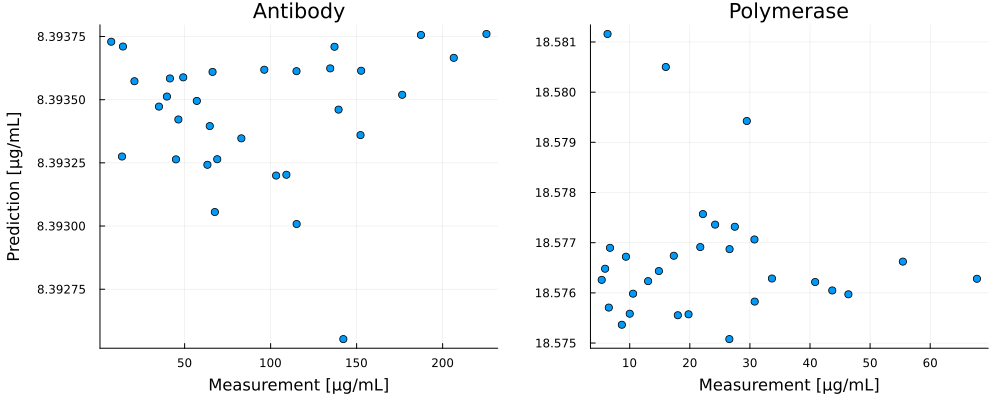

In [9]:
p_A = scatter(df_A.expression, df_A.predictions_μg_per_mL, xlabel = "Measurement [µg/mL]", ylabel = "Prediction [µg/mL]", title = "Antibody", label = false)
p_P = scatter(df_P.expression, df_P.predictions_μg_per_mL, xlabel = "Measurement [µg/mL]",  title = "Polymerase", label = false)
plot(p_A, p_P, layout = (1,2), size = (1000,400), left_margin = 5mm, bottom_margin = 5mm)